# PBMC 3k single-cell RNA-seq walkthrough (Scanpy)

This notebook steps through the same functions `run_pipeline.py` uses, showing the intermediate results and the reasoning behind each decision.

**Data:** 10x Genomics *3k PBMCs from a Healthy Donor* (v1 chemistry, hg19). Peripheral blood mononuclear cells are a standard benchmark because their cell types and marker genes are well known, so the result can be checked against biology.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd, scanpy as sc
from IPython.display import Image, display
from pbmc_pipeline import qc, analysis, annotate, plots
from pbmc_pipeline.config import Config

cfg = Config()
sc.settings.verbosity = 0
FIG = cfg.figures_dir
FIG.mkdir(parents=True, exist_ok=True)

## 1. Load counts and look at quality metrics

Three per-cell metrics separate real, healthy cells from problems:
- **Genes detected** too low: empty droplet or debris. Too high: possibly two cells in one droplet.
- **UMI counts**: total captured molecules; tracks genes detected.
- **% mitochondrial reads**: high values mean the cell membrane broke and cytoplasmic RNA leaked out.

In [2]:
adata = qc.add_qc_metrics(qc.load_counts(cfg))
adata.obs = adata.obs.join(qc.flag_cells(adata, cfg))
print(adata)
adata.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt']].describe().round(1)

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'too_few_genes', 'too_many_genes', 'high_mito', 'fail_fixed_qc', 'mad_outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X), 'counts'


,n_genes_by_counts,total_counts,pct_counts_mt
count,2700.0,2700.0,2700.0
mean,847.0,2366.9,2.2
std,282.1,1094.3,1.2
min,212.0,548.0,0.0
25%,690.0,1757.8,1.5
50%,817.0,2197.0,2.0
75%,953.2,2763.0,2.6
max,3422.0,15844.0,22.6


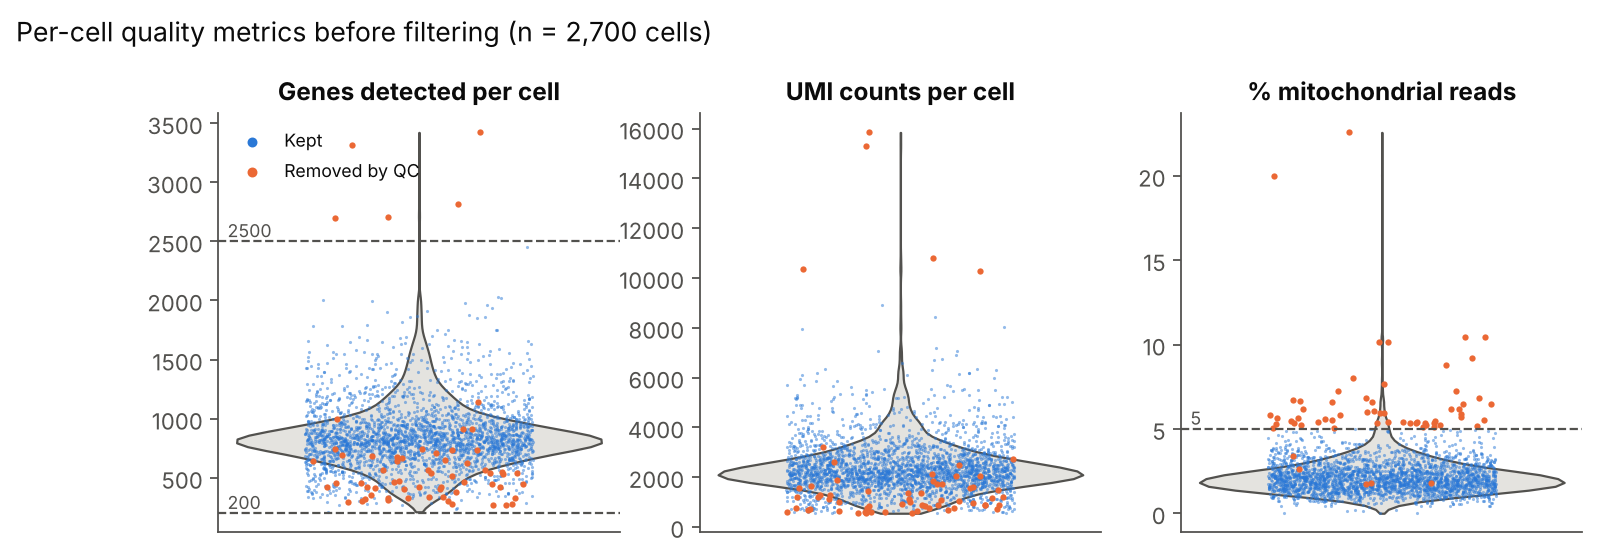

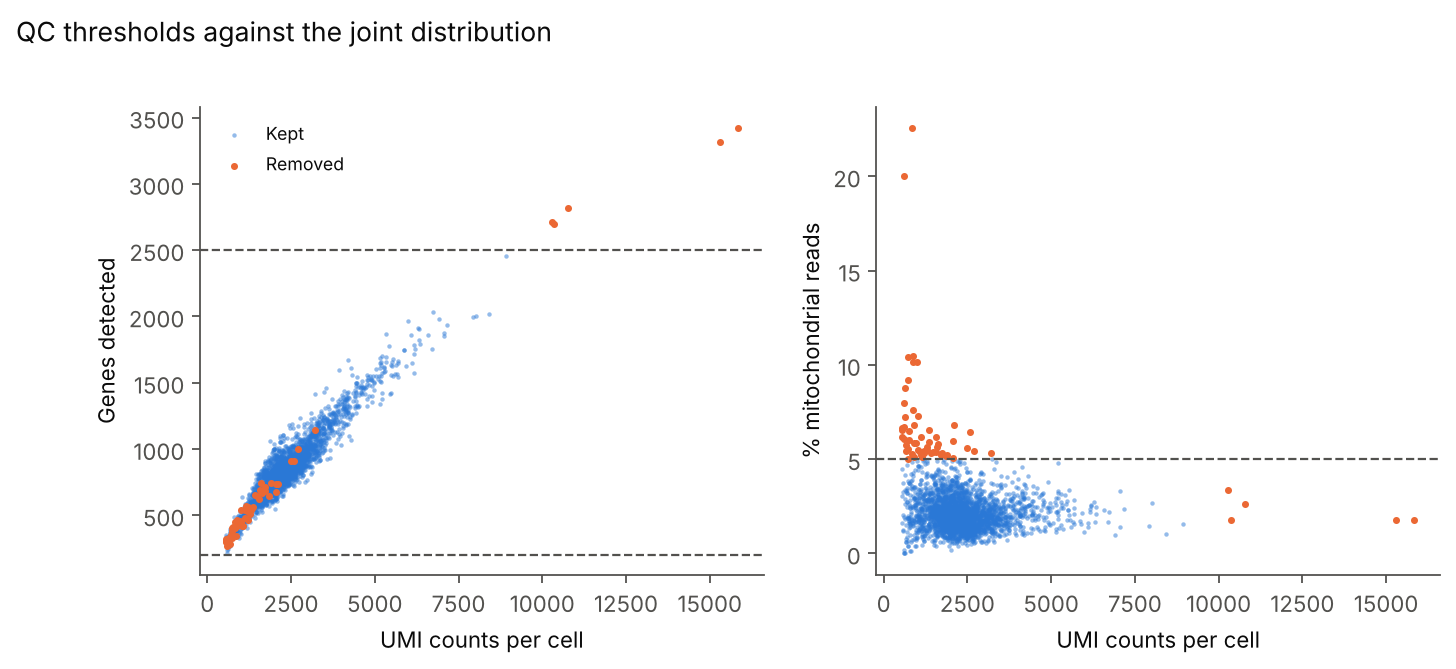

In [3]:
plots.qc_distributions(adata, cfg, FIG / '01_qc_distributions.png')
plots.qc_scatter(adata, cfg, FIG / '02_qc_scatter.png')
display(Image(FIG / '01_qc_distributions.png'), Image(FIG / '02_qc_scatter.png'))

The 5% mitochondrial cutoff removes a tail of low-count, high-mito cells (damaged cells), and the 2,500-gene cap removes a handful of unusually large cells that are likely multiplets. A data-driven 5-MAD rule is computed alongside for comparison; it flags a similar but not identical set, which is why the fixed thresholds are written down in `config.py` rather than left implicit.

## 2. Filter cells and genes, remove doublets

Scrublet simulates artificial doublets by adding random pairs of real cells, then flags real cells that look more like the simulated doublets than like single cells.

In [4]:
adata.obs = adata.obs.drop(columns=['too_few_genes','too_many_genes','high_mito','fail_fixed_qc','mad_outlier'])
adata, qc_log = qc.run_qc(adata, cfg)
qc_log

,step,count
0,Cells loaded,2700
1,Genes loaded,32738
2,Cells with < 200 genes,0
3,Cells with > 2500 genes,5
4,Cells with > 5% mitochondrial reads,57
5,Cells removed by fixed QC (any rule),62
6,Cells flagged by 5-MAD rule (for comparison),85
7,Genes removed (in < 3 cells),19082
8,Predicted doublets removed (Scrublet),31
9,Cells retained,2607


## 3. Normalize, select variable genes, reduce dimensions

Counts are scaled to 10,000 per cell and log-transformed so cells with different sequencing depth are comparable. The 2,000 most variable genes carry the cell-type signal; PCA compresses them, and the first 30 components (past the elbow) build the neighbor graph used for UMAP and clustering.

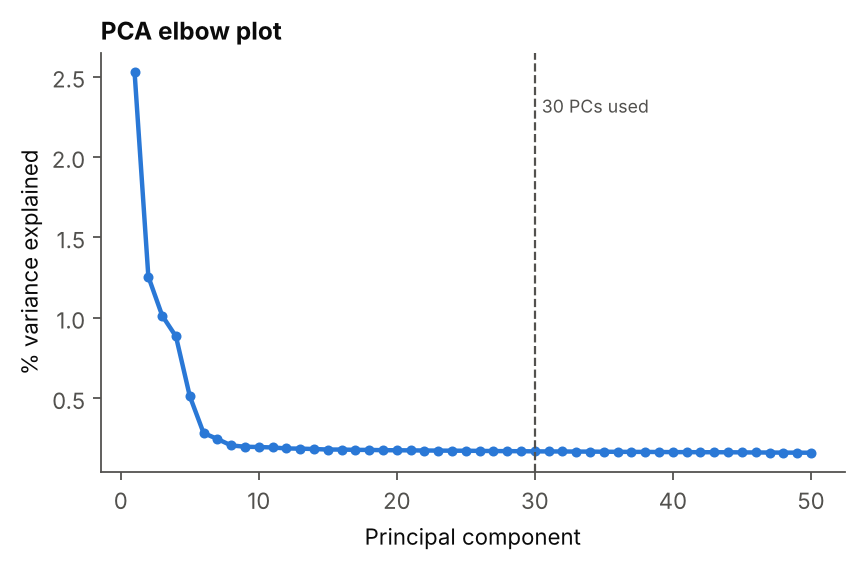

In [5]:
adata = analysis.normalize_and_select(adata, cfg)
adata = analysis.embed(adata, cfg)
plots.pca_variance(adata, cfg, FIG / '03_pca_variance.png')
display(Image(FIG / '03_pca_variance.png'))

## 4. Choose a clustering resolution, and check it is reproducible

Leiden clustering has a resolution knob and a random seed. For each resolution the data are clustered with five seeds and the agreement between runs is measured with the adjusted Rand index (1.0 = identical).

,resolution,n_clusters_median,mean_pairwise_ARI,min_pairwise_ARI
0,0.2,5,0.951,0.880
1,0.4,6,0.996,0.994
2,0.6,7,0.979,0.962
3,0.8,9,0.753,0.657
4,1.0,9,0.902,0.870
5,1.4,10,0.820,0.759


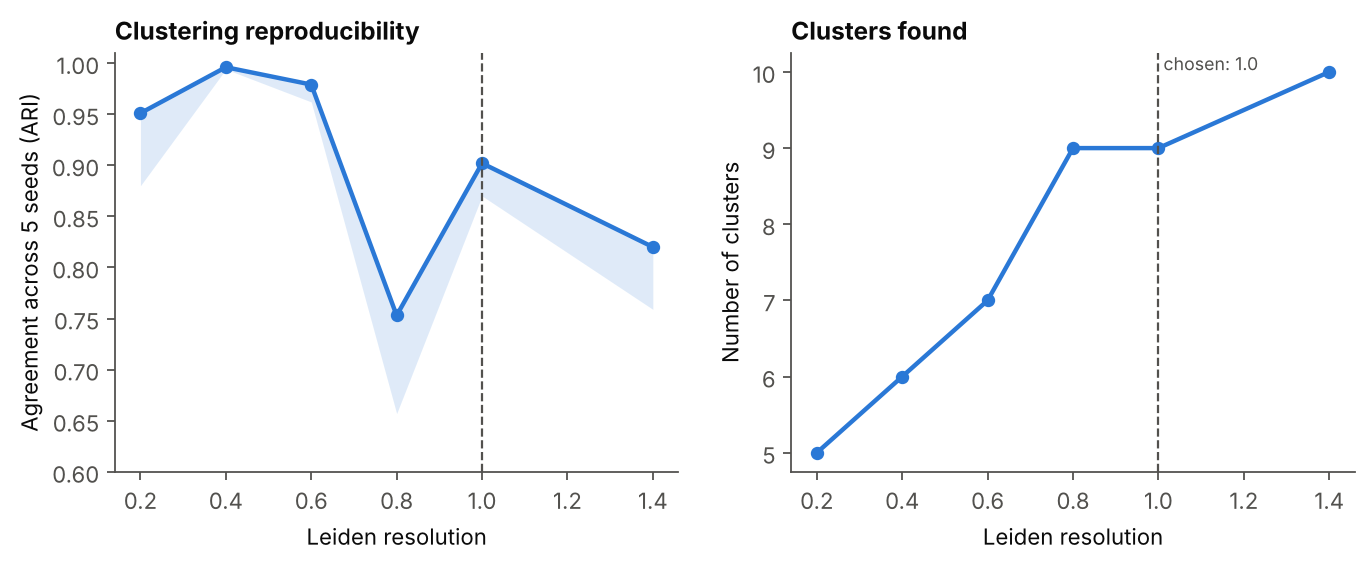

In [6]:
stab = analysis.cluster_with_stability(adata, cfg)
plots.stability(stab, cfg.leiden_resolution, FIG / '04_cluster_stability.png')
display(stab, Image(FIG / '04_cluster_stability.png'))

Resolutions 0.4-0.6 are the most reproducible, but they merge naive and memory CD4 T cells and fold CD8 T cells in with NK cells, which the marker genes clearly separate. Resolution 1.0 is the lowest setting that resolves the expected PBMC populations while staying reproducible (ARI ≈ 0.90); 0.8 sits on a boundary where a cluster splits differently from seed to seed.

## 5. Marker genes and cell type annotation

Each cluster is tested against all other cells (Wilcoxon rank-sum). Separately, every cell is scored for nine canonical PBMC marker sets, and each cluster takes the label with the highest average score. When the winner beats the runner-up by less than 0.25, the cluster is marked **review** rather than trusted blindly.

In [7]:
markers = analysis.find_markers(adata, cfg)
markers.groupby('leiden', observed=True)['gene'].apply(lambda g: ', '.join(g.head(6))).to_frame('top markers')

,top markers
leiden,
0,"RPS12, RPS27, RPL32, RPS6, RPS14, RPS25"
1,"LTB, IL32, LDHB, CD3D, IL7R, TPT1"
2,"CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1, HLA-DQA1"
3,"CCL5, NKG7, CST7, B2M, GZMA, CTSW"
4,"LST1, COTL1, FCER1G, AIF1, FTH1, IFITM3"
5,"NKG7, GZMB, PRF1, GNLY, CTSW, CST7"
6,"S100A9, S100A8, LYZ, TYROBP, FTL, FCN1"
7,"HLA-DPB1, HLA-DPA1, HLA-DRA, HLA-DRB1, HLA-DQA..."
8,"PPBP, NRGN, GPX1, RGS10, CALM3, TAGLN2"


In [8]:
ann = annotate.annotate_clusters(adata, cfg)
ann

,leiden,n_cells,cell_type,top_score,runner_up,runner_up_score,margin,confidence
0,0,632,Naive CD4 T,0.108,Memory CD4 T,0.093,0.014,review
1,1,527,Memory CD4 T,0.539,Naive CD4 T,-0.020,0.559,high
2,2,327,B,1.455,Platelet,-0.027,1.481,high
3,3,309,CD8 T,0.846,NK,0.705,0.142,review
4,4,203,FCGR3A Monocyte,1.700,CD14 Monocyte,0.695,1.006,high
5,5,139,NK,2.643,Platelet,-0.065,2.708,high
6,6,422,CD14 Monocyte,2.798,FCGR3A Monocyte,0.452,2.346,high
7,7,33,Dendritic,1.598,CD14 Monocyte,0.710,0.888,high
8,8,15,Platelet,4.371,CD8 T,0.443,3.928,high


### Reviewing the low-confidence calls

In [9]:
evidence = annotate.review_evidence(adata, ann, cfg)
evidence

,leiden,call,candidate,gene,mean_expr_in_cluster,mean_expr_elsewhere,pct_cells_expressing
0,0,Naive CD4 T,Naive CD4 T,IL7R,1.27,0.74,58.1
1,0,Naive CD4 T,Naive CD4 T,CCR7,0.93,0.19,47.2
2,0,Naive CD4 T,Naive CD4 T,LEF1,0.69,0.17,36.2
3,0,Naive CD4 T,Naive CD4 T,TCF7,0.72,0.32,38.8
4,0,Naive CD4 T,Naive CD4 T,CD4,0.11,0.22,6.2
5,0,Naive CD4 T,Memory CD4 T,IL7R,1.27,0.74,58.1
6,0,Naive CD4 T,Memory CD4 T,S100A4,1.57,2.96,65.8
7,0,Naive CD4 T,Memory CD4 T,AQP3,0.42,0.28,22.0
8,0,Naive CD4 T,Memory CD4 T,CD40LG,0.25,0.16,14.4
9,0,Naive CD4 T,Memory CD4 T,CD4,0.11,0.22,6.2


- **Cluster 0 (Naive vs. Memory CD4 T):** higher CCR7 and LEF1 than the rest of the data and about half the S100A4 level, the pattern of naive T cells. Its top differential genes are ribosomal proteins, which is also typical of resting naive T cells. **Call kept: Naive CD4 T.**
- **Cluster 3 (CD8 T vs. NK):** expresses CD8A/CD8B and GZMK, which NK cells lack, while sharing cytotoxic genes (NKG7, CCL5) with NK cells. Cluster 5 has far higher GNLY and FCGR3A. **Call kept: CD8 T.**

## 6. Results

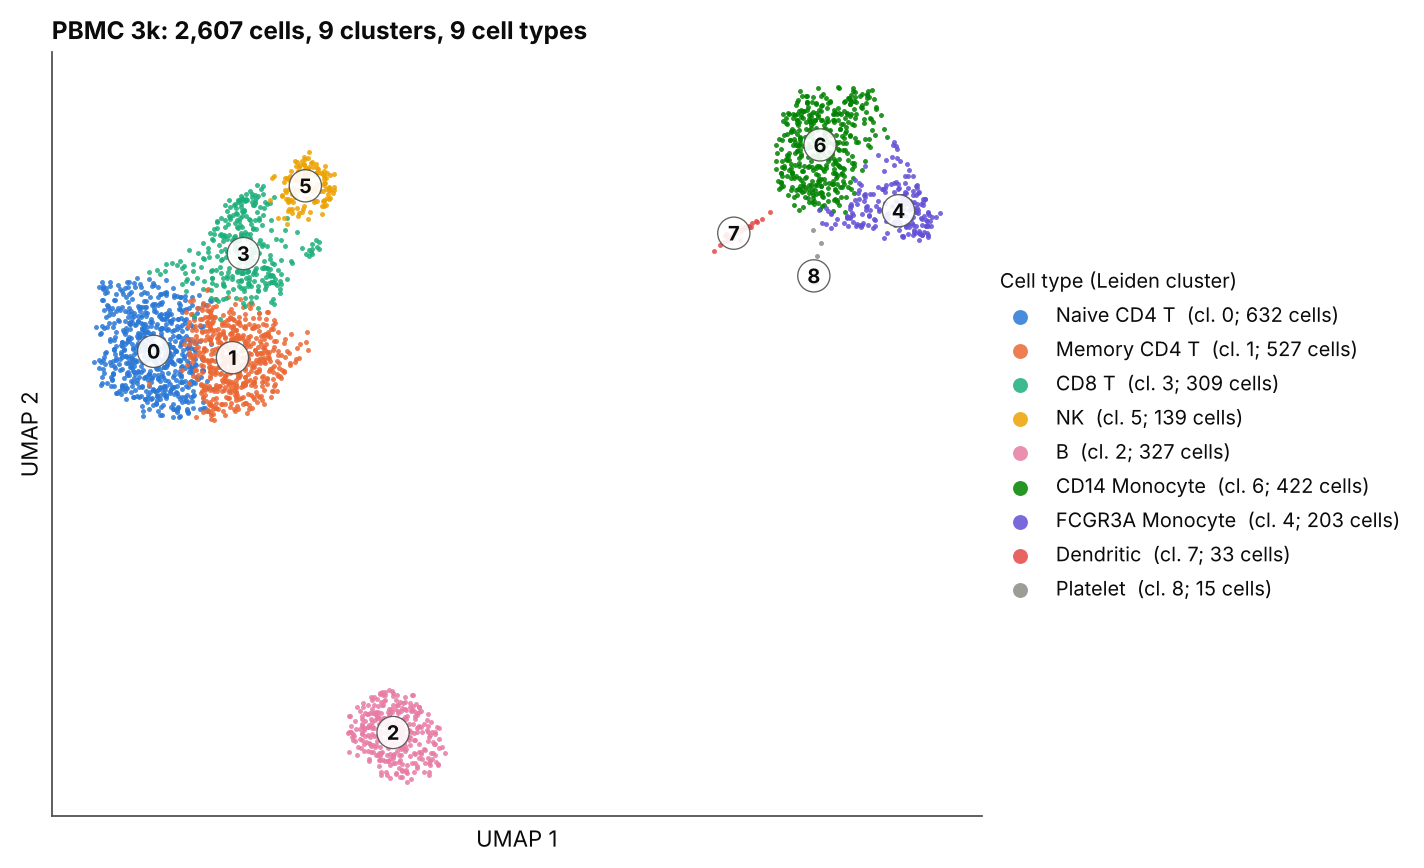

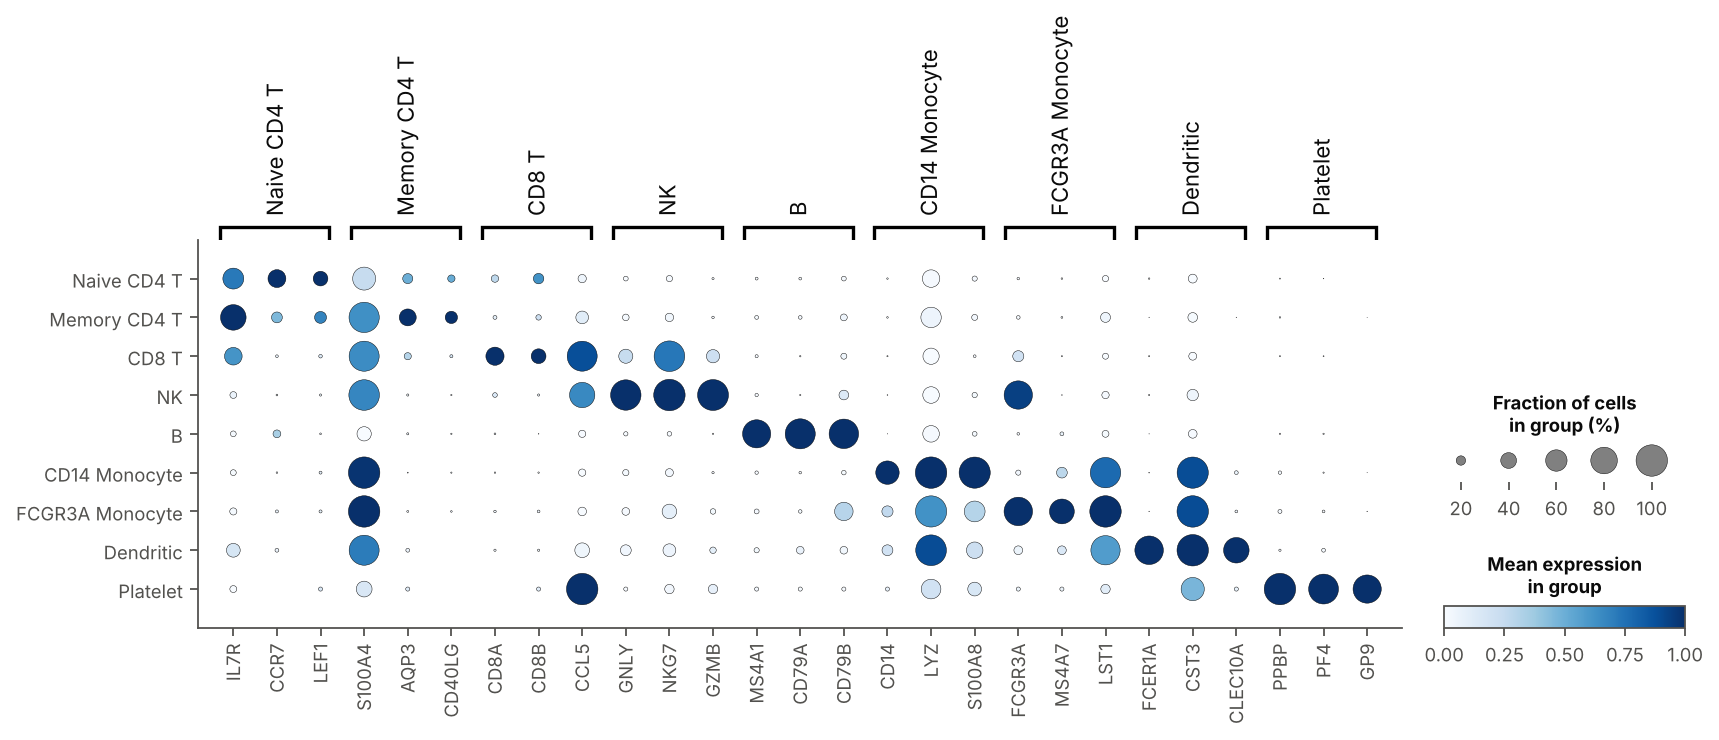

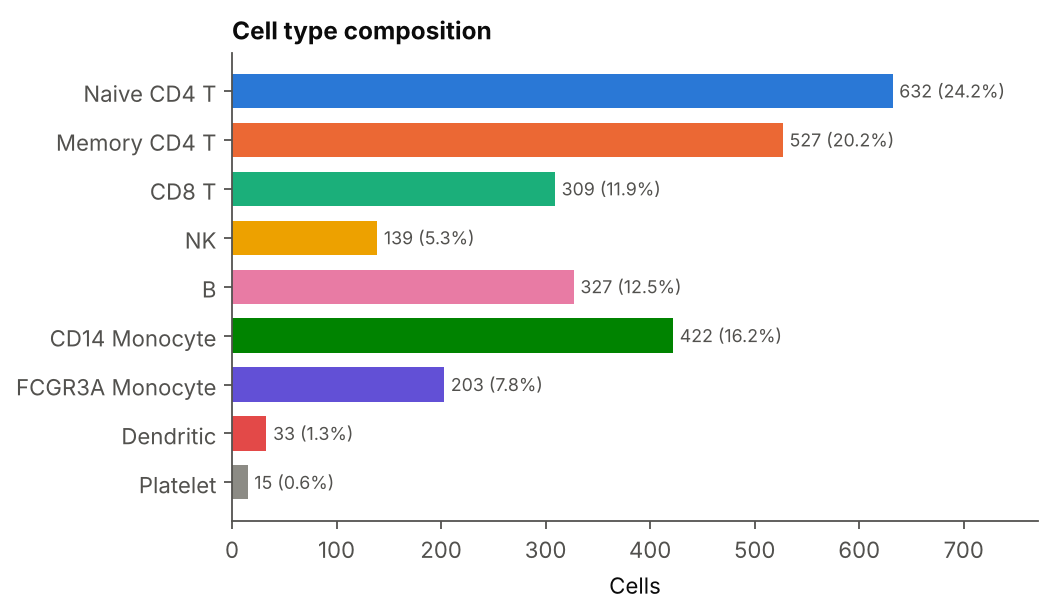

In [10]:
order = [ct for ct in cfg.marker_sets if ct in set(adata.obs['cell_type'])]
colors = plots.cell_type_colors(order)
adata.obs['cell_type'] = adata.obs['cell_type'].cat.reorder_categories(order)
plots.umap_cell_types(adata, colors, FIG / '05_umap_cell_types.png')
plots.marker_dotplot(adata, cfg, order, FIG / '06_marker_dotplot.png')
plots.composition(adata, colors, FIG / '08_cell_type_composition.png')
display(Image(FIG / '05_umap_cell_types.png'), Image(FIG / '06_marker_dotplot.png'), Image(FIG / '08_cell_type_composition.png'))

## Limitations

- One donor and one sample, so there is no batch correction or between-condition comparison.
- Annotation depends on a curated marker list; rare or activated states outside that list would be forced into the closest type. A reference-based method (e.g. CellTypist) would be a useful cross-check.
- Naive vs. memory CD4 T is a gradient rather than a clean split in this data, as the review step shows.